# ***Do Strong Subscription, High Listing Day Pop, and Market Condition on Listing Day Predict Better Returns in 1 Year?***

## **Data and Libraries Import**

`Libraries Import`

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


import warnings
warnings.filterwarnings('ignore')

import os
from dotenv import load_dotenv
from pathlib import Path

from sqlalchemy import create_engine, text

`Initializing the env-variables so that no one sees the actual credentials`

In [2]:
env_path = Path.cwd()/"github_repo_cloned"/"ipo_reality_check"/".env"
load_dotenv(env_path)


host = os.getenv("DB_HOST")
user = os.getenv("DB_USER")
port = os.getenv("DB_PORT")
password = os.getenv("DB_PASSword")
db = os.getenv("DB_NAME")


`Creating the engine to connect with the database`

In [3]:
engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{db}")

def sql(query, engine = engine):
    with engine.connect() as conn:
        df = pd.read_sql(text(query),conn)
    return df

`Importing the data`

In [4]:
data = sql('''select * from regression_data''')

data.head()

,company,listing_date,excess_return,listing_pop,subscription,vix_close,nifty_open,nifty_close
0,Xelpmoc Design & Tech Ltd.,2019-02-04,1.35,5.00,2.72,15.72,10876.75,10912.25
1,Chalet Hotels Ltd.,2019-02-07,6.54,0.24,1.41,15.44,11070.45,11069.40
2,Rail Vikas Nigam Ltd.,2019-04-11,14.79,0.26,1.70,20.96,11592.55,11596.70
3,Metropolis Healthcare Ltd.,2019-04-15,54.83,0.19,3.68,21.39,11667.00,11690.35
4,Polycab India Ltd.,2019-04-16,38.55,3.44,36.51,21.69,11736.20,11787.15


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294 entries, 0 to 293
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   company        294 non-null    object 
 1   listing_date   294 non-null    object 
 2   excess_return  293 non-null    float64
 3   listing_pop    293 non-null    float64
 4   subscription   294 non-null    float64
 5   vix_close      294 non-null    float64
 6   nifty_open     294 non-null    float64
 7   nifty_close    294 non-null    float64
dtypes: float64(6), object(2)
memory usage: 18.5+ KB


In [6]:
pd.set_option('display.max_columns',None)

## **Initial Data Checking**

`Null Value Checking and removing`

In [7]:
data.isnull().sum().reset_index(name = 'null_values')

,index,null_values
0,company,0
1,listing_date,0
2,excess_return,1
3,listing_pop,1
4,subscription,0
5,vix_close,0
6,nifty_open,0
7,nifty_close,0


In [8]:
data = data.dropna()

In [9]:
data[data['company'].duplicated()]

,company,listing_date,excess_return,listing_pop,subscription,vix_close,nifty_open,nifty_close


`Adding Nifty return on listing day, as the market condition`

In [10]:
data['nifty_day_return'] = ((data['nifty_close']-data['nifty_open'])/data['nifty_open']).mul(100).round(2)

`Checking the skew in subscription, to decide on log`

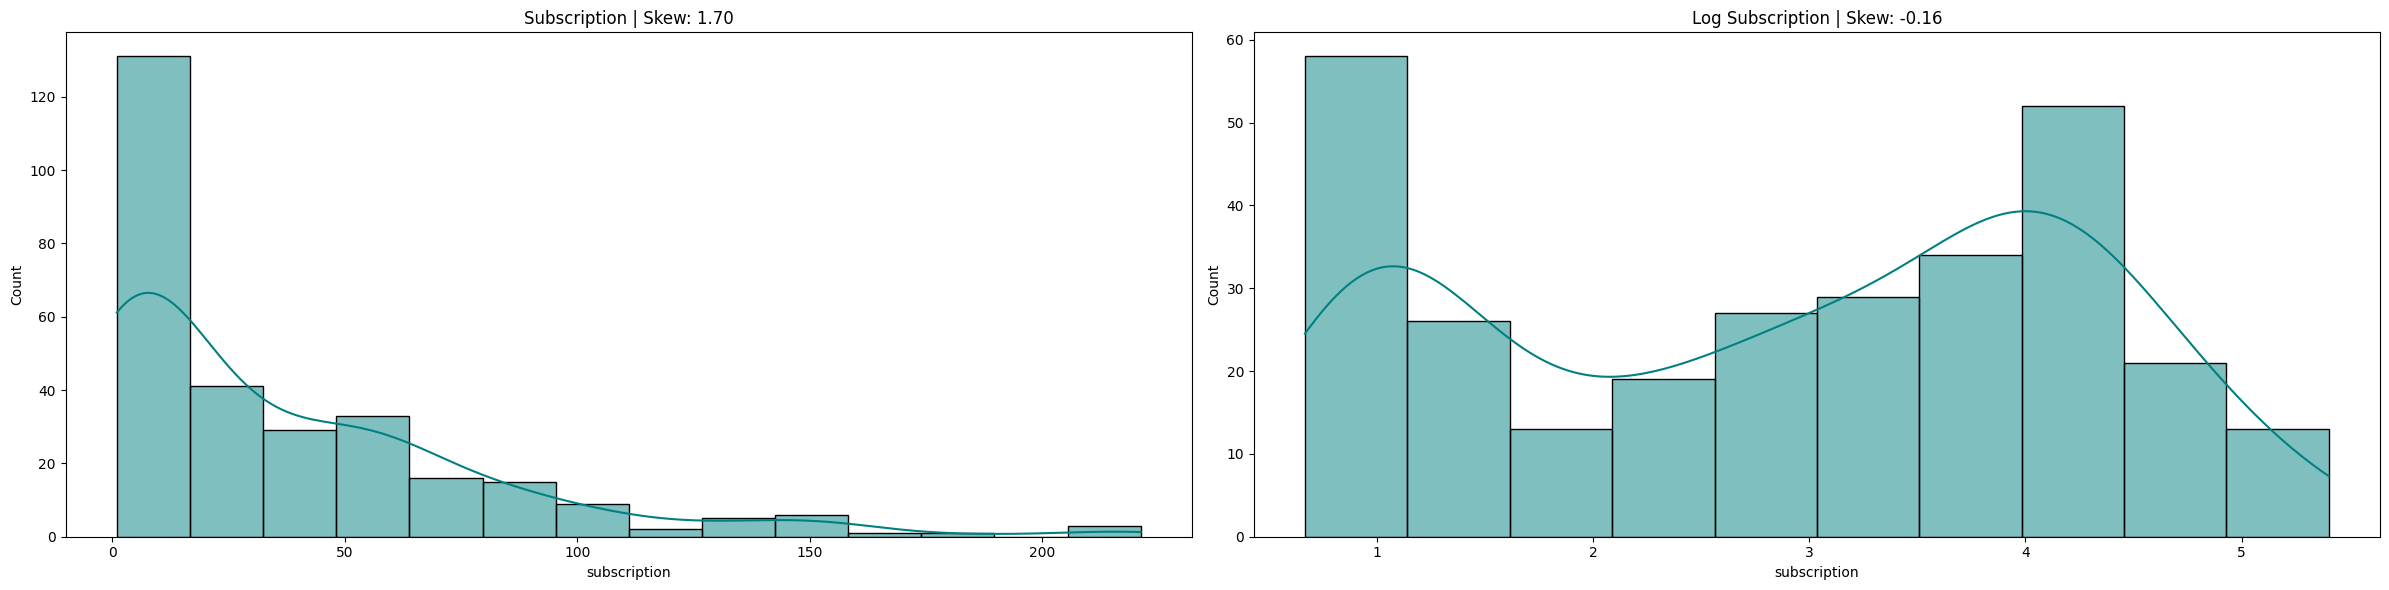

In [11]:
fig, axes = plt.subplots(1,2, figsize = (24,6))

sns.histplot(data['subscription'], kde = True, color = 'teal', ax = axes[0])
axes[0].set_title(f"Subscription | Skew: {data['subscription'].skew():.2f}")

sns.histplot(np.log1p(data['subscription']), kde = True, color = 'teal', ax = axes[1])
axes[1].set_title(f"Log Subscription | Skew: {np.log1p(data['subscription']).skew():.2f}")

plt.tight_layout()
plt.show()

In [12]:
data['log_subscription'] = np.log1p(data['subscription'])

---
Subscription is heavily right skewed, using the log version in the model

---

`Keeping only the modelling columns`

In [13]:
features = ['log_subscription', 'listing_pop', 'vix_close', 'nifty_day_return']
target = 'excess_return'

model_df = data[['company','listing_date', target] + features]
model_df.head()

,company,listing_date,excess_return,log_subscription,listing_pop,vix_close,nifty_day_return
0,Xelpmoc Design & Tech Ltd.,2019-02-04,1.35,1.313724,5.00,15.72,0.33
1,Chalet Hotels Ltd.,2019-02-07,6.54,0.879627,0.24,15.44,-0.01
2,Rail Vikas Nigam Ltd.,2019-04-11,14.79,0.993252,0.26,20.96,0.04
3,Metropolis Healthcare Ltd.,2019-04-15,54.83,1.543298,0.19,21.39,0.20
4,Polycab India Ltd.,2019-04-16,38.55,3.624608,3.44,21.69,0.43


`Outlier checking in the target and features`

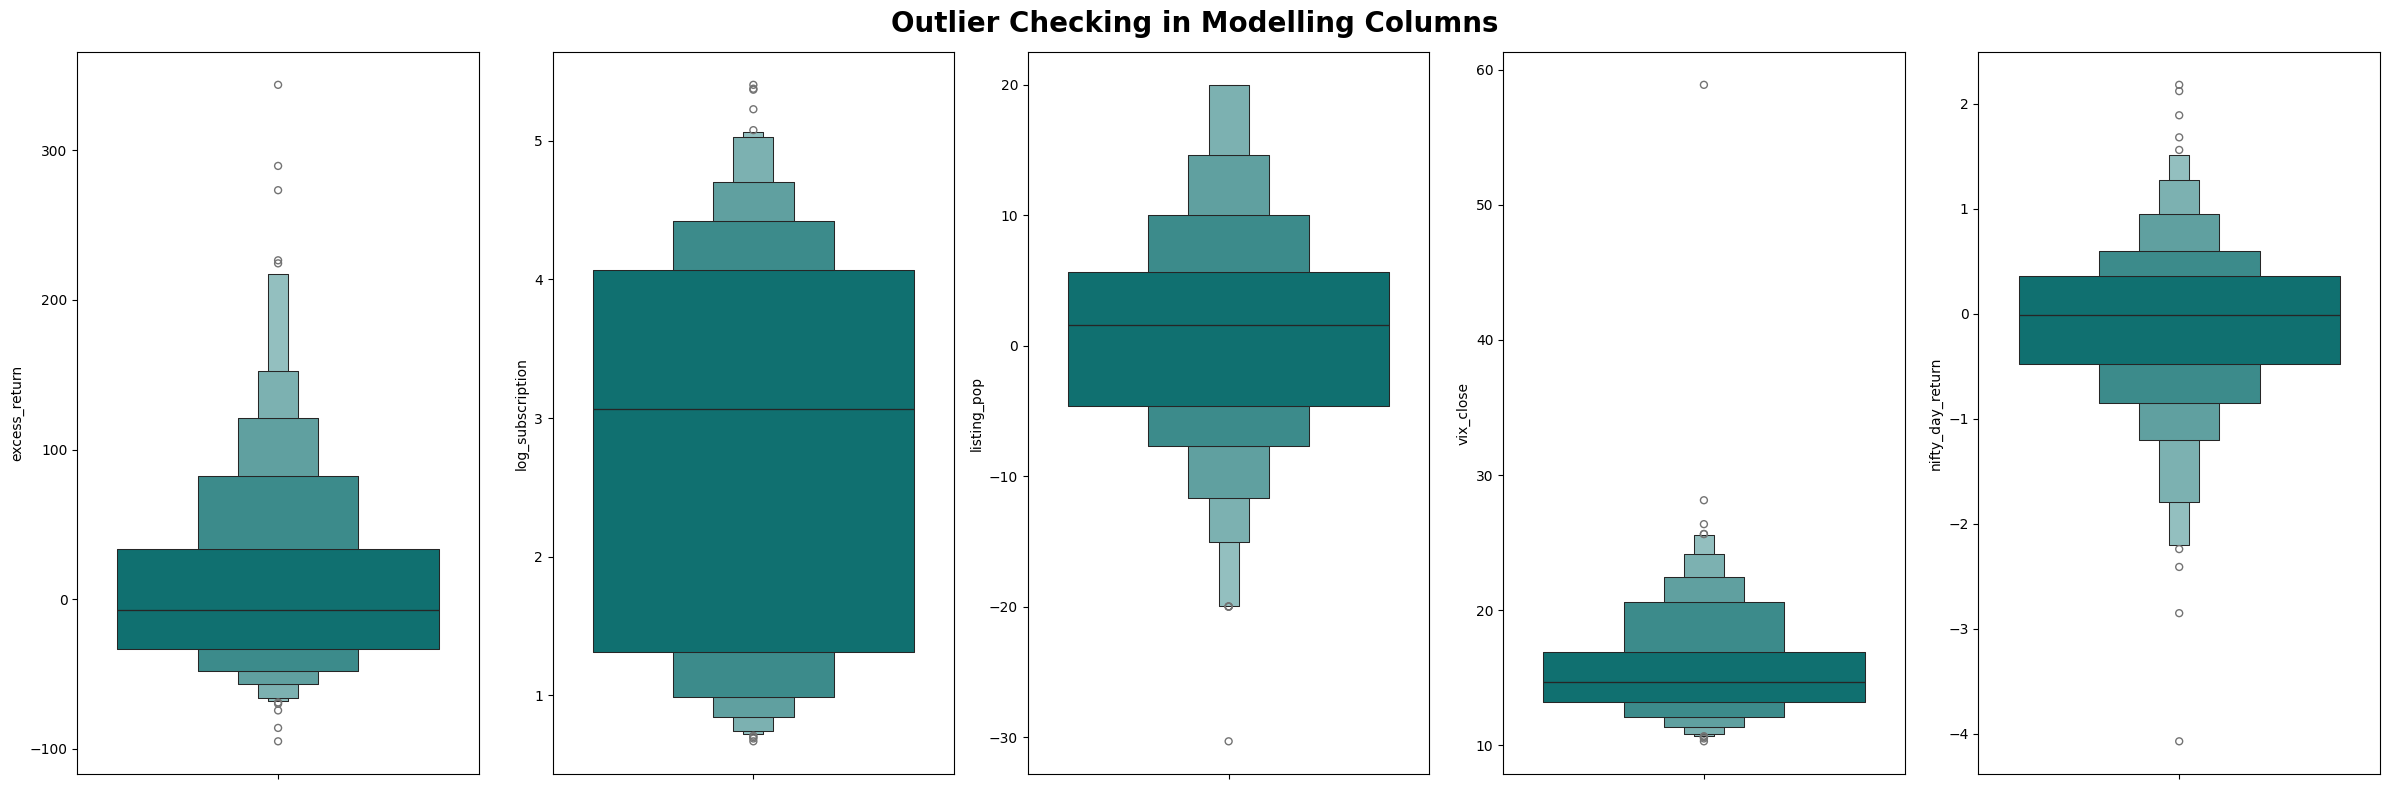

In [14]:
columns = [target] + features

fig, axes = plt.subplots(1,5, figsize= (24,8))
axes = axes.flatten()

for ax, col in zip(axes, columns):
    sns.boxenplot(y = col, data = model_df, color = "teal", ax = ax)
plt.suptitle("Outlier Checking in Modelling Columns",fontsize = 20, fontweight = 'bold')
plt.tight_layout()
plt.show()

In [15]:
q1 = model_df[columns].quantile(0.25)
q3 = model_df[columns].quantile(0.75)
iqr = q3 - q1

((model_df[columns] < q1 - 1.5*iqr) | (model_df[columns] > q3 + 1.5*iqr)).sum().reset_index(name = 'outlier_cnt')

,index,outlier_cnt
0,excess_return,15
1,log_subscription,0
2,listing_pop,4
3,vix_close,17
4,nifty_day_return,14


---
There are certainly some outliers, but these might be helpful in prediction so I am keeping them

---

## **Analysis and Results**

`Checking the correlation between the target and features`

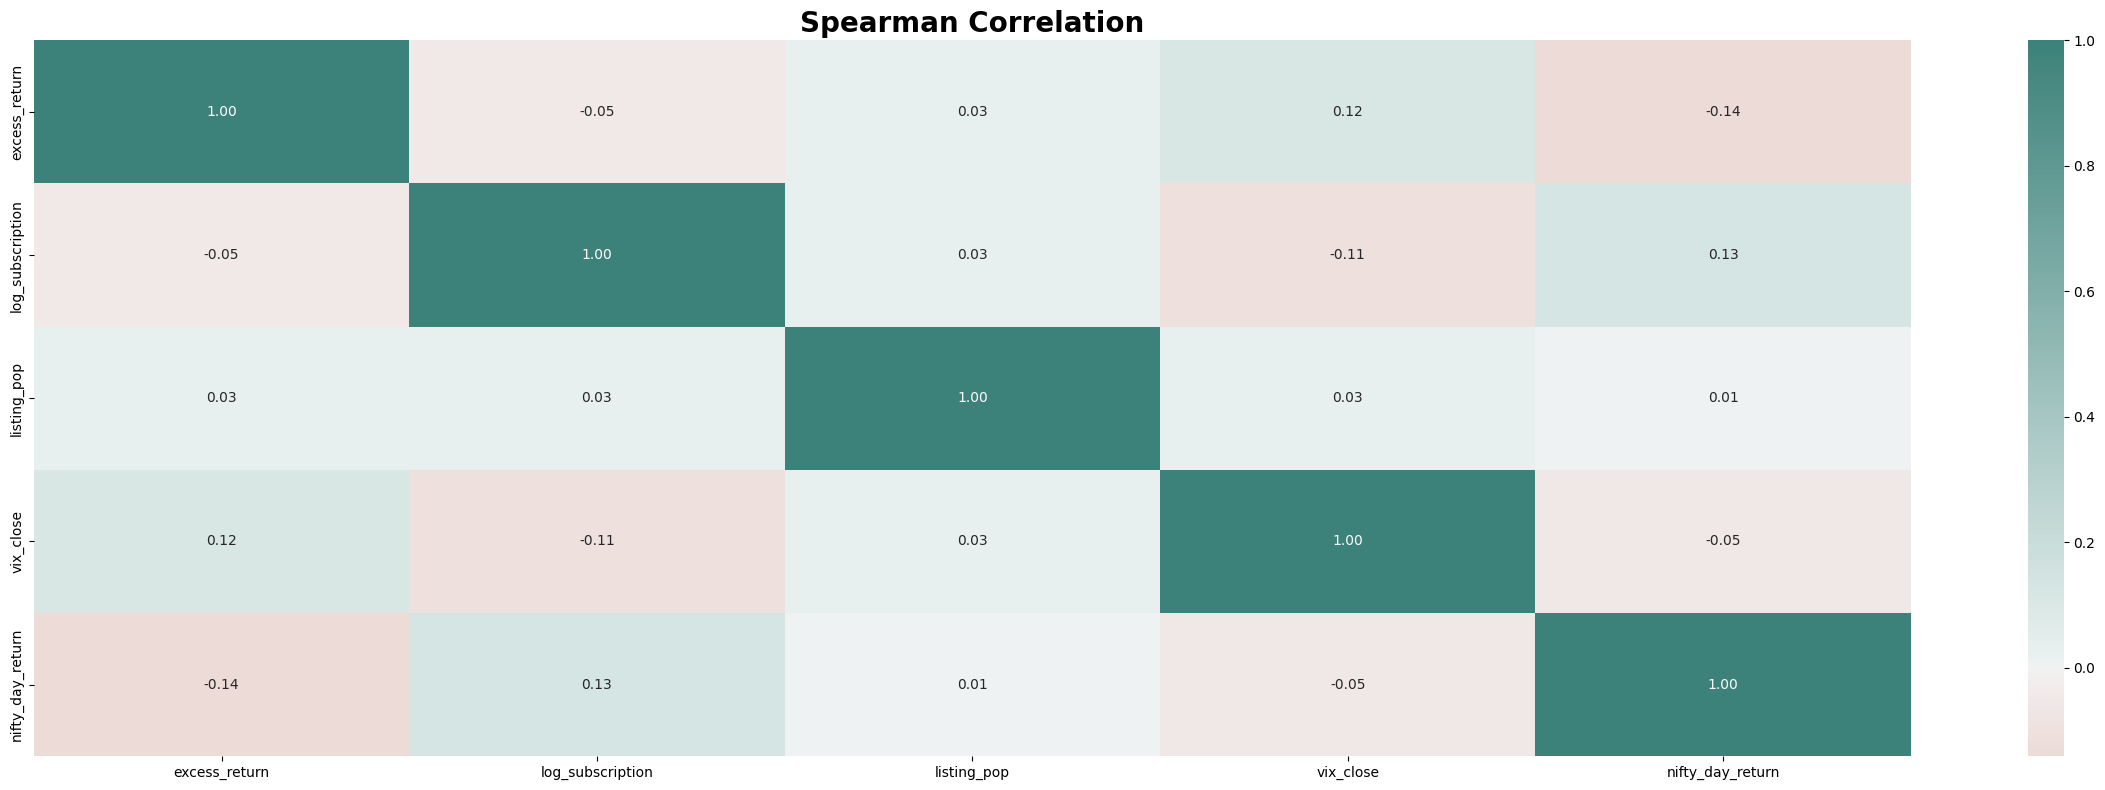

In [16]:
plt.figure(figsize=(24,8))
sns.heatmap(model_df[[target] + features].corr(method='spearman'),
            annot = True, fmt = '.2f', center = 0,
            cmap = sns.diverging_palette(20, 180, as_cmap = True))
plt.title("Spearman Correlation", fontsize = 20, fontweight = 'bold')
plt.tight_layout()
plt.show()

`VIF check for multicollinearity in features`

In [17]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = sm.add_constant(model_df[features])

vif = pd.DataFrame({
    'feature': X.columns,
    'vif': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
}).query("feature != 'const'").round(2)

vif

,feature,vif
1,log_subscription,1.01
2,listing_pop,1.00
3,vix_close,1.08
4,nifty_day_return,1.08


---
All VIF is close to 1, so there is no risk of multicolinearity

---

`OLS with robust standard errors (HC3), features are standardized so the coefficients are comparable`

In [18]:
X = model_df[features]
X_std = sm.add_constant((X - X.mean()) / X.std())
y = model_df[target]

model = sm.OLS(y, X_std).fit(cov_type = 'HC3')
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          excess_return   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                    0.9214
Date:                Sat, 31 Oct 2026   Prob (F-statistic):              0.452
Time:                        21:23:01   Log-Likelihood:                -1629.3
No. Observations:                 292   AIC:                             3269.
Df Residuals:                     287   BIC:                             3287.
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                9.3170      3.838  

---
None of the 4 features significantly predict 1 year excess return, and together they explain only 2% of the variation

---

`Residual check`

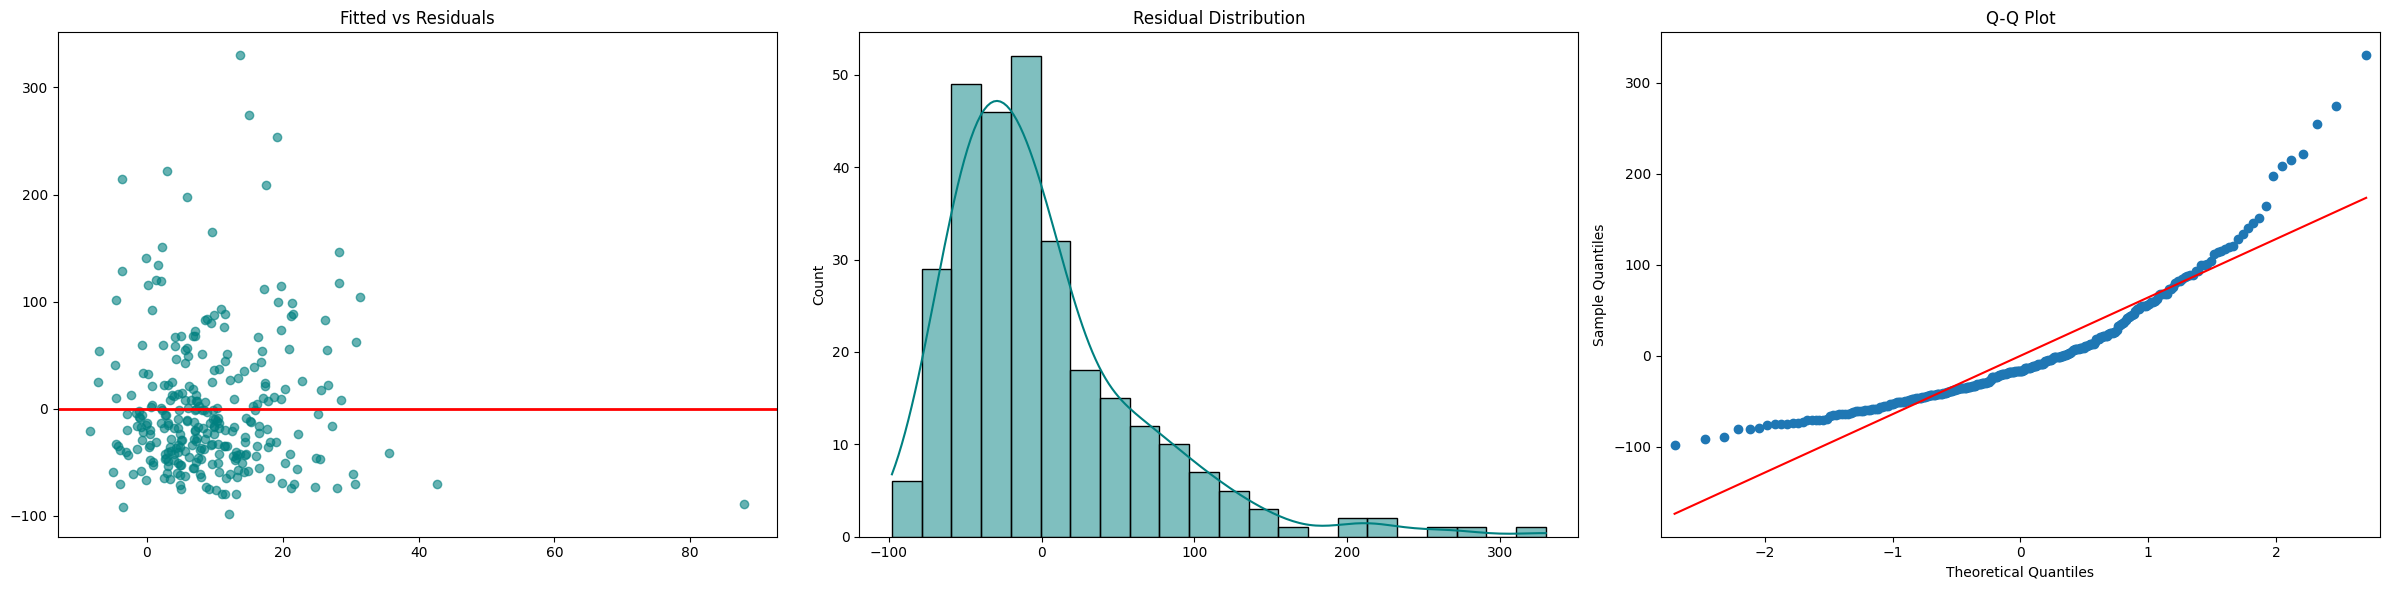

In [19]:
resid = model.resid
fitted = model.fittedvalues

fig, axes = plt.subplots(1,3, figsize = (24,6))

axes[0].scatter(fitted, resid, color = 'teal', alpha = 0.6)
axes[0].axhline(0, color = 'red', linewidth = 2)
axes[0].set_title("Fitted vs Residuals")

sns.histplot(resid, kde = True, color = 'teal', ax = axes[1])
axes[1].set_title("Residual Distribution")

sm.qqplot(resid, line = 's', ax = axes[2])
axes[2].set_title("Q-Q Plot")

plt.tight_layout()
plt.show()

---
Residuals are right skewed because of a few very high returns

---

`Coefficients with p-values and confidence intervals`

In [20]:
ci = model.conf_int()

coef_table = pd.DataFrame({
    'coef': model.params,
    'ci_low': ci[0],
    'ci_high': ci[1],
    'p_value': model.pvalues
}).drop('const').round(3).reset_index().rename(columns = {'index':'feature'})

coef_table

,feature,coef,ci_low,ci_high,p_value
0,log_subscription,-0.127,-7.427,7.173,0.973
1,listing_pop,5.836,-2.463,14.135,0.168
2,vix_close,6.346,-5.026,17.718,0.274
3,nifty_day_return,-2.874,-11.839,6.091,0.530


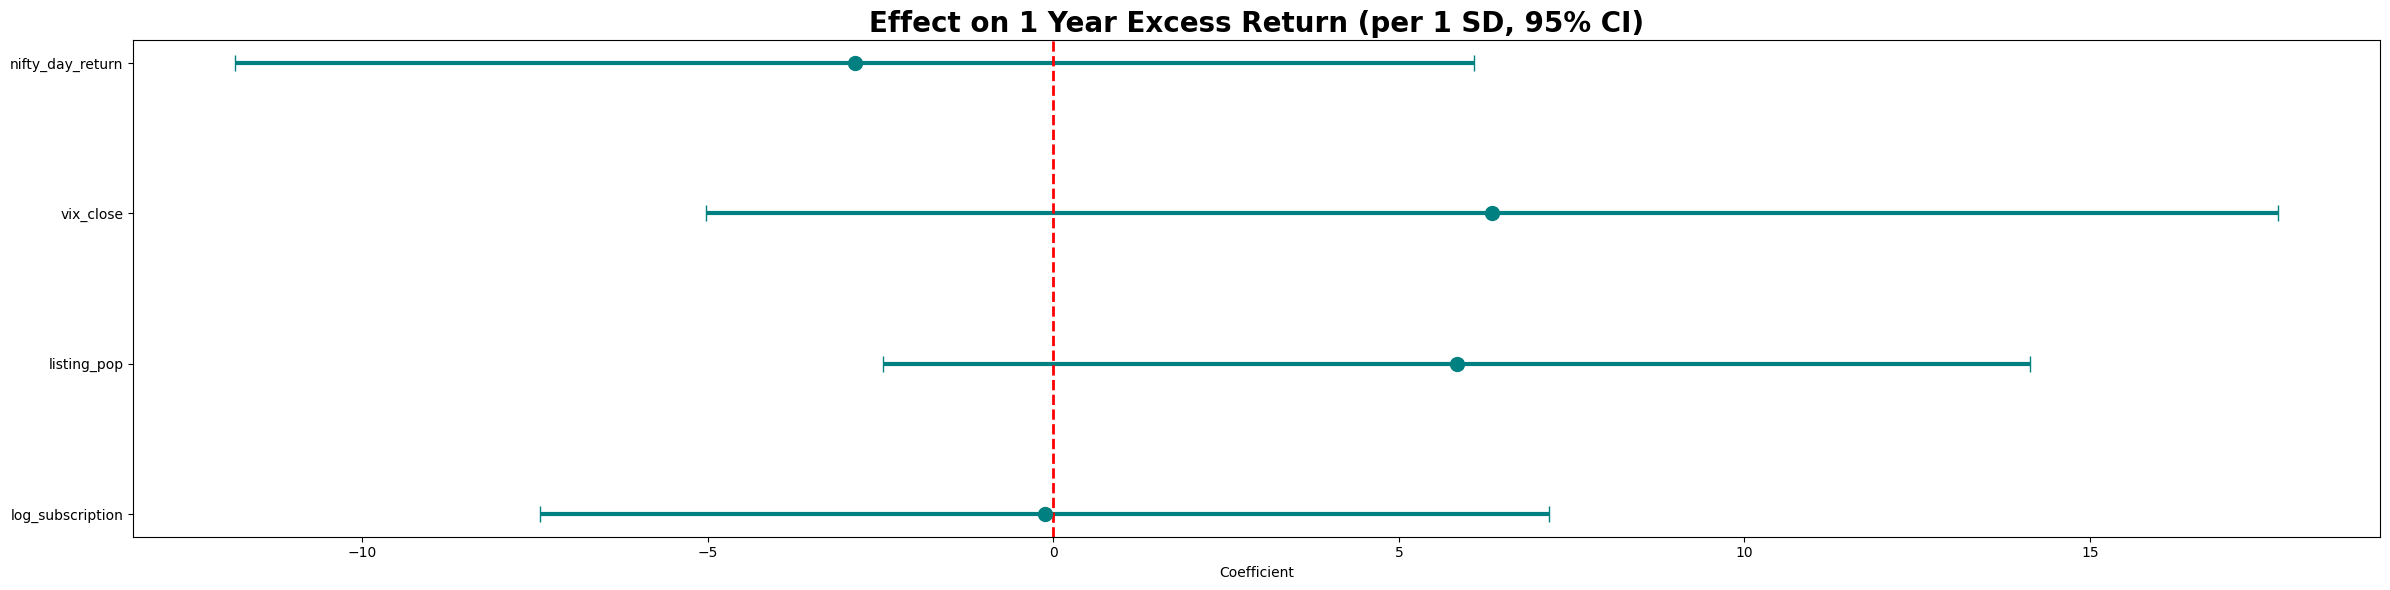

In [21]:
plt.figure(figsize=(24,6))
plt.errorbar(x = coef_table['coef'], y = coef_table['feature'],
             xerr = [coef_table['coef'] - coef_table['ci_low'], coef_table['ci_high'] - coef_table['coef']],
             fmt = 'o', color = 'teal', ecolor = 'teal', capsize = 6, linewidth = 3, markersize = 10)
plt.axvline(0, color = 'red', linestyle = '--', linewidth = 2)
plt.title("Effect on 1 Year Excess Return (per 1 SD, 95% CI)", fontsize = 20, fontweight = 'bold')
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

---
The higher co-efficients are just random in this sample, verified by the p-values

---

Quick non-linear check, cross validated R2 of Linear vs Random Forest

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

lr_r2 = cross_val_score(LinearRegression(), X, y, cv = 5, scoring = 'r2').mean()
rf_r2 = cross_val_score(RandomForestRegressor(n_estimators = 200, max_depth = 4, random_state = 42), X, y, cv = 5, scoring = 'r2').mean()

print(f"Linear CV R2: {lr_r2:.3f}\nRandom Forest CV R2: {rf_r2:.3f}")

Linear CV R2: -0.059
Random Forest CV R2: -0.094


---
Even Random Forest cannot predict 1 year excess return on unseen data

---